## Libraries

In [2]:
import random
import numpy as np
import torch
from pathlib import Path
import kagglehub
from dataclasses import dataclass, replace, asdict
import json
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.utils as vutils
from PIL import Image
import matplotlib.pyplot as plt
import time
import torch.nn as nn
import torch.optim as optim

## Config Cell

In [ ]:
@dataclass(frozen= True)
class Config:
    # Reproducibility
    SEED: int = 42

    # Dataset
    DATASET: str = "jessicali9530/celeba-dataset"
    EXPECTED_IMAGES: int = 202_599
    DATA_DIR: Path = (Path.cwd().parent / "Data" / "celeba").resolve()

    # Run / output paths
    RUN_NAME: str = "baseline"
    ARTIFACT_ROOT: Path = (Path.cwd() / "artifacts" / "GAN").resolve()

    # Data Pipeline
    IMAGE_SIZE: int = 64
    CHANNELS: int = 3
    BATCH_SIZE: int = 128
    NUM_WORKERS: int = 4
    CROP_SIZE: int = 148

    # Model
    LATENT_DIM: int = 100
    G_FEATURES: int = 64
    D_FEATURES: int = 64

    # Optimizer / init 
    LR: int = 2e-4
    BETA1: int = 0.5
    BETA2: int = 0.999
    INIT_STD: int = 0.02

    # Training
    EPOCHS: int = 25
    LOG_EVERY = 100
    
    def __post_init__(self):
        assert self.IMAGE_SIZE == 64

    @property
    def RUN_DIR(self) -> Path:
        return self.ARTIFACT_ROOT / self.RUN_NAME

    @property
    def CKPT_DIR(self) -> Path:
       return self.RUN_DIR / "checkpoints" 

    @property
    def SAMPLE_DIR(self) -> Path:
        return self.RUN_DIR / "samples"

    @property
    def PLOT_DIR(self) -> Path:
        return self.RUN_DIR / "plots"

    def make_dirs(self):
        for d in (self.RUN_DIR, self.CKPT_DIR,self.SAMPLE_DIR, self.PLOT_DIR):
            d.mkdir(parents = True, exist_ok = True)

    def save(self):
        path = self.RUN_DIR / "config.json"
        path.write_text(json.dumps(asdict(self), indent = 2, default = str))
        return path

cfg = Config()
cfg.make_dirs()
cfg.save()
print(f"Run: {cfg.RUN_NAME} -> {cfg.RUN_DIR}")


Run: baseline -> /home/harsh/Work/Notebooks/Projects/Notebooks/artifacts/GAN/baseline


In [4]:
# Checks For GPU
seed = cfg.SEED
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)   # safe to call even without a GPU

# Falls back to CPU so other people can still run the notebook
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA (built with):", torch.version.cuda)
    print(f"VRAM free/total: {free / 1e9:.1f} / {total / 1e9:.1f} GB")

PyTorch: 2.14.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 3060
CUDA (built with): 13.0
VRAM free/total: 11.8 / 12.9 GB


## Data 

In [5]:
# Relative to the notebook (Projects/Notebooks), so it works on any machine
data = cfg.DATA_DIR
image_count = cfg.EXPECTED_IMAGES

data.mkdir(parents=True, exist_ok=True)

def count_jpgs(root):
    return sum(1 for _ in root.rglob("*.jpg"))

existing = count_jpgs(data)

if existing >= image_count:
    print(f"Dataset already present ({existing:,} images). Skipping download.")
else:
    print(f"Found {existing:,} images, expected {image_count:,}. Downloading...")
    kagglehub.dataset_download(
        cfg.DATASET,
        output_dir=str(data),
        force_download=existing > 0,   # re-fetch only if a partial copy exists
    )

# Locate the folder that actually holds the JPEGs (the zip may nest it twice)
first = next(data.rglob("*.jpg"), None)
if first is None:
    raise FileNotFoundError(f"No JPEGs found under {data}. Download failed.")

IMG_DIR = first.parent
n_images = sum(1 for _ in IMG_DIR.glob("*.jpg"))
if n_images < image_count:
    raise RuntimeError(f"Only {n_images:,} images in {IMG_DIR}. Delete {data} and rerun.")

print(f"Ready: {n_images:,} images in {IMG_DIR}")


Dataset already present (202,599 images). Skipping download.
Ready: 202,599 images in /home/harsh/Work/Notebooks/Projects/Data/celeba/img_align_celeba/img_align_celeba


## Pipeline

In [6]:
class CelebADataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.paths = sorted(Path(img_dir).glob("*.jpg"))
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB") 
        return self.transform(img) if self.transform else img

transform = transforms.Compose([
    transforms.CenterCrop(cfg.CROP_SIZE),
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * cfg.CHANNELS, [0.5] * cfg.CHANNELS),
])

dataset = CelebADataset(IMG_DIR, transform)

loader = DataLoader(
    dataset,
    batch_size= cfg.BATCH_SIZE,
    shuffle= True,
    drop_last= True,
    num_workers= cfg.NUM_WORKERS,
    pin_memory= True,
    persistent_workers= cfg.NUM_WORKERS > 0,
)

print(f"Images: {len(dataset):,} | Batches/epoch: {len(loader):,}")

Images: 202,599 | Batches/epoch: 1,582


torch.Size([128, 3, 64, 64]) min=-1.00 max=1.00


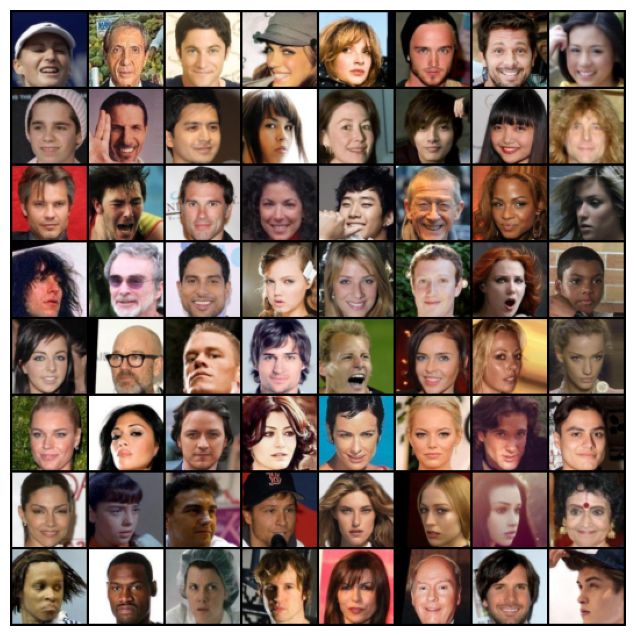

In [7]:
batch = next(iter(loader))
print(batch.shape, f"min={batch.min():.2f} max={batch.max():.2f}")   # [128, 3, 64, 64], within [-1, 1]

grid = vutils.make_grid(batch[:64], nrow=8, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(8, 8)); plt.axis("off")
plt.imshow(grid.permute(1, 2, 0)); plt.show()

## Model Generator

In [8]:
class Generator(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        nz, f, nc = cfg.LATENT_DIM, cfg.G_FEATURES, cfg.CHANNELS
        self.nz = nz
        self.net = nn.Sequential(
            # [B, nz, 1, 1] -> [B, 8f, 4, 4]
            nn.ConvTranspose2d(nz, f * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(f * 8), nn.ReLU(True),
            # -> [B, 4f, 8, 8]
            nn.ConvTranspose2d(f * 8, f * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(f * 4), nn.ReLU(True),
            # -> [B, 2f, 16, 16]
            nn.ConvTranspose2d(f * 4, f * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(f * 2), nn.ReLU(True),
            # -> [B, f, 32, 32]
            nn.ConvTranspose2d(f * 2, f, 4, 2, 1, bias=False),
            nn.BatchNorm2d(f), nn.ReLU(True),
            # -> [B, nc, 64, 64], values in [-1, 1]
            nn.ConvTranspose2d(f, nc, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z.view(z.size(0), self.nz, 1, 1))
        

In [9]:
netG = Generator(cfg).to(device)
z = torch.randn(cfg.BATCH_SIZE, cfg.LATENT_DIM, device=device)
with torch.no_grad():
    out = netG(z)
print(out.shape, f"min={out.min():.2f} max={out.max():.2f}")   # [128, 3, 64, 64], inside [-1, 1]
print(f"Generator params: {sum(p.numel() for p in netG.parameters()):,}")

torch.Size([128, 3, 64, 64]) min=-1.00 max=1.00
Generator params: 3,576,704


## Discriminator

In [10]:
class Discriminator(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        nc, f = cfg.CHANNELS, cfg.D_FEATURES
        self.net = nn.Sequential(
            nn.Conv2d(nc, f, 4, 2, 1, bias= False),
            nn.LeakyReLU(0.2, inplace= True),

            nn.Conv2d(f, f * 2, 4, 2, 1, bias= False),
            nn.BatchNorm2d(f*2), nn.LeakyReLU(0.2, inplace= True),

            nn.Conv2d(f*2, f*4, 4, 2, 1, bias= False),
            nn.BatchNorm2d(f*4), nn.LeakyReLU(0.2, inplace= True),

            nn.Conv2d(f*4, f*8, 4, 2, 1, bias= False),
            nn.BatchNorm2d(f*8), nn.LeakyReLU(0.2, inplace= True),

            nn.Conv2d(f*8, 1, 4, 1, 0, bias= False)
        )

    def forward(self, x):
        return self.net(x).view(-1)

In [11]:
netD = Discriminator(cfg).to(device)
real = next(iter(loader)).to(device)
with torch.no_grad():
    fake = netG(torch.randn(cfg.BATCH_SIZE, cfg.LATENT_DIM, device=device))
    print("real:", netD(real).shape, "| fake:", netD(fake).shape)   # both [128]
print(f"Discriminator params: {sum(p.numel() for p in netD.parameters()):,}")

real: torch.Size([128]) | fake: torch.Size([128])
Discriminator params: 2,765,568


## Optimizer Cell

In [12]:
def weights_init(m):
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight, 0.0, cfg.INIT_STD)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight, 1.0, cfg.INIT_STD)
        nn.init.zeros_(m.bias)

netG = Generator(cfg).to(device)
netD = Discriminator(cfg).to(device)
netG.apply(weights_init)
netD.apply(weights_init)

criterion = nn.BCEWithLogitsLoss()
optG = optim.Adam(netG.parameters(), lr=cfg.LR, betas=(cfg.BETA1, cfg.BETA2))
optD = optim.Adam(netD.parameters(), lr=cfg.LR, betas=(cfg.BETA1, cfg.BETA2))

In [13]:
g_conv = netG.net[0].weight
d_conv = netD.net[0].weight
g_bn = netG.net[1].weight
print(f"G conv: mean={g_conv.mean():.4f} std={g_conv.std():.4f}")   # ~0.0000, ~0.0200
print(f"D conv: mean={d_conv.mean():.4f} std={d_conv.std():.4f}")   # ~0.0000, ~0.0200
print(f"G BN weight: mean={g_bn.mean():.3f}")                       # ~1.000

with torch.no_grad():
    out = netG(torch.randn(cfg.BATCH_SIZE, cfg.LATENT_DIM, device=device))
print(out.shape, f"min={out.min():.2f} max={out.max():.2f}")         # should no longer sit at exactly -1/1

G conv: mean=0.0000 std=0.0200
D conv: mean=-0.0003 std=0.0202
G BN weight: mean=0.999
torch.Size([128, 3, 64, 64]) min=-0.84 max=0.83


## Training